In [42]:
import csv
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import CategoricalNB
from sklearn.metrics import roc_auc_score, f1_score, accuracy_score, confusion_matrix

### Define constants

In [43]:
filename = './data/agaricus-lepiota.data'

feature_names = [
    "cap-shape", "cap-surface", "cap-color", "bruises", "odor",
    "gill-attachment", "gill-spacing", "gill-size", "gill-color",
    "stalk-shape", "stalk-root", "stalk-surface-above-ring",
    "stalk-surface-below-ring", "stalk-color-above-ring",
    "stalk-color-below-ring", "veil-type", "veil-color",
    "ring-number", "ring-type", "spore-print-color",
    "population", "habitat",
]

alpha_exponents = list(range(-15, 6)) # alpha = 2^-15, 2^-14, ..., 2^

In [44]:
# Read the file
rows = []
with open(filename) as csvfile:
    for row in csv.reader(csvfile, delimiter= ','):
        if len(row) >0:
            rows.append(row)

num_samples = len(rows)
num_features = len(rows[0])-1

# Map category letters to an integer for each feature
category_maps = [{} for _ in range(num_features)]
for row in rows:
    for j in range(num_features):
        letter = row[j+1]
        if letter not in category_maps[j]:
            category_maps[j][letter] = len(category_maps[j])

# Number of categories per feature in the whole dataset
n_categories = np.array([len(m) for m in category_maps])

# Build X and y
label_map = {'e':0, 'p':1} # poison = positive class
X = np.zeros((num_samples, num_features), dtype=int)
y = np.zeros(num_samples, dtype=int)
for i, row in enumerate(rows):
    y[i] = label_map[row[0]]
    for j in range(num_features):
        X[i, j] = category_maps[j][row[j+1]]

print("n=%d, d=%d, fraction poisonous=%.3f" % (num_samples, num_features, y.mean()))


n=8124, d=22, fraction poisonous=0.482


## Helper functions
`min_categories = n_categories` tells `CategoricalNB` how many categories each feature has in the dataset. Without it, categories that doesn't appear in the training split but appears in the test split raises an index error. With it, the category gets the probability alpha/(class_count+alpha*n_categories).

In [45]:
def sweep_alpha(X_train, y_train, X_test, y_test):
    """Train one CategoricalNB per alpha. return lists of test AUC, accuracy, and F1."""
    aucs, accs, f1s = [], [], []

    for exponent in alpha_exponents:
        model = CategoricalNB(alpha=2.0**exponent, min_categories=n_categories)
        model.fit(X_train, y_train)

        prob_ispoison = model.predict_proba(X_test)[:, 1]
        y_pred = model.predict(X_test)

        aucs.append(roc_auc_score(y_test, prob_ispoison))
        accs.append(accuracy_score(y_test, y_pred))
        f1s.append(f1_score(y_test, y_pred))
    return aucs, accs, f1s

def plot_scores(aucs, accs, f1s, title):
    plt.figure()
    plt.plot(alpha_exponents, aucs, marker='s', label='ROC AUC')
    plt.plot(alpha_exponents, accs, marker='p', label='Accuracy')
    plt.plot(alpha_exponents, f1s, marker='^', label='F1')
    plt.xlabel('log2(alpha)')
    plt.ylabel('Test score')
    plt.title(title)
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

def report_best_model(X_train, y_train, X_test, y_test, aucs, accs, f1s):
    """Print metrics, confusion matrix, and params for the alpha with the max AUC."""
    best = int(np.argmax(aucs)) # first (smallest) alpha if there's ties
    best_alpha = 2.0**alpha_exponents[best]

    print("Best alpha by AUC: 2^%d = %g" % (alpha_exponents[best], best_alpha))
    print("AUC=%.4f, Accuracy = %.4f, F1=%.4f" % (aucs[best], accs[best], f1s[best]))

    num_tied = sum(1 for a in aucs if abs(a-aucs[best]) < 1e-12)
    print("number of alphas tied at this AUC: ", num_tied)

    model = CategoricalNB(alpha=best_alpha, min_categories=n_categories)
    model.fit(X_train, y_train)

    print("Confusion matrix (rows: true [edible, poison], cols: predicted): ")
    print(confusion_matrix(y_test, model.predict(X_test)))

    print("P(edible) = %.4f, P(poison) = %.4f " % tuple(np.exp(model.class_log_prior_)))
    return model

def print_parameters(model):
    """Print P(feature = category | class) for each feature"""
    for j, name in enumerate(feature_names):
        probs = np.exp(model.feature_log_prob_[j]) # shape (2, n_categories[j])
        letter_of = {idx: letter for letter, idx in category_maps[j].items()}
        print(name)
        for k in range(probs.shape[1]):
            print("%-2s edible =%.4f poisonous = %.4f" % (letter_of.get(k, '?'), probs[0, k], probs[1, k]))

## Part 1

train: 6499  test: 1625


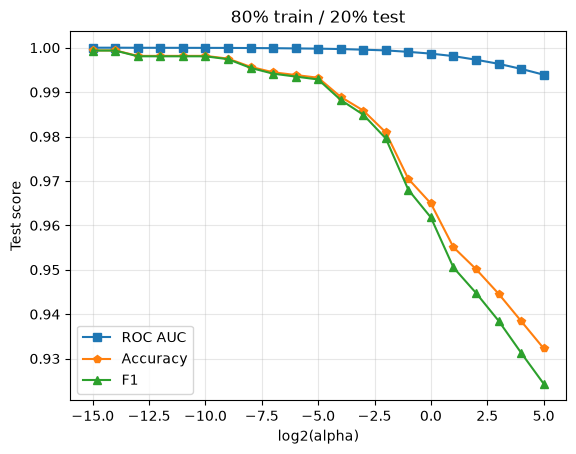

Best alpha by AUC: 2^-15 = 3.05176e-05
AUC=1.0000, Accuracy = 0.9994, F1=0.9994
number of alphas tied at this AUC:  2
Confusion matrix (rows: true [edible, poison], cols: predicted): 
[[851   1]
 [  0 773]]
P(edible) = 0.5164, P(poison) = 0.4836 
cap-shape
x  edible =0.4592 poisonous = 0.4353
b  edible =0.0951 poisonous = 0.0124
s  edible =0.0074 poisonous = 0.0000
f  edible =0.3832 poisonous = 0.3993
k  edible =0.0551 poisonous = 0.1521
c  edible =0.0000 poisonous = 0.0010
cap-surface
s  edible =0.2649 poisonous = 0.3627
y  edible =0.3591 poisonous = 0.4423
f  edible =0.3760 poisonous = 0.1938
g  edible =0.0000 poisonous = 0.0013
cap-color
n  edible =0.3010 poisonous = 0.2603
y  edible =0.0921 poisonous = 0.1654
w  edible =0.1675 poisonous = 0.0818
g  edible =0.2485 poisonous = 0.2094
e  edible =0.1502 poisonous = 0.2272
p  edible =0.0137 poisonous = 0.0232
b  edible =0.0116 poisonous = 0.0299
u  edible =0.0036 poisonous = 0.0000
c  edible =0.0080 poisonous = 0.0029
r  edible =0.0039 

In [46]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.80, random_state=0)
print("train:", len(y_train), " test:", len(y_test))
aucs, accs, f1s = sweep_alpha(X_train, y_train, X_test, y_test)
plot_scores(aucs, accs, f1s, "80% train / 20% test")

model_80 = report_best_model(X_train, y_train, X_test, y_test, aucs, accs, f1s)
print_parameters(model_80)

## Part 2
1% train / 99% test. Same experiment as previous,c ategories missing from the small training set are handled by 'min_categories'

train: 81  test: 8043


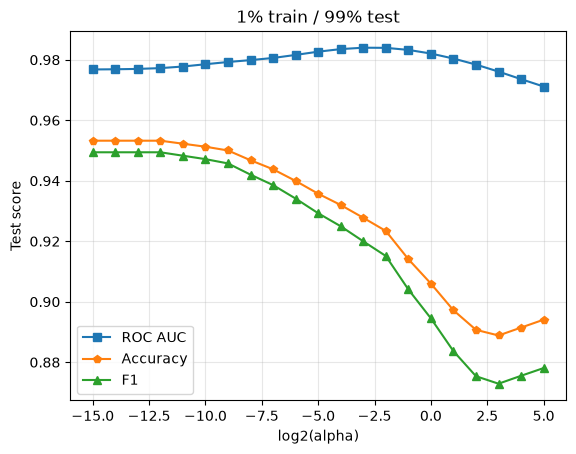

Best alpha by AUC: 2^-3 = 0.125
AUC=0.9840, Accuracy = 0.9278, F1=0.9200
number of alphas tied at this AUC:  1
Confusion matrix (rows: true [edible, poison], cols: predicted): 
[[4122   40]
 [ 541 3340]]
P(edible) = 0.5679, P(poison) = 0.4321 
Best alpha AUC over 20 seeds: mean 0.9853 std=0.0079


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.01, random_state=0)
print("train:", len(y_train), " test:", len(y_test))
aucs, accs, f1s = sweep_alpha(X_train, y_train, X_test, y_test)
plot_scores(aucs, accs, f1s, "1% train / 99% test")

model_1 = report_best_model(X_train, y_train, X_test, y_test, aucs, accs, f1s)

# Let's see how much the result varies, since 81 sample split will likely be noisy.
best_aucs = []
for seed in range(20):
    X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.01, random_state=seed)
    aucs, accs, f1s = sweep_alpha(X_train, y_train, X_test, y_test)
    best_aucs.append(max(aucs))
print("Best alpha AUC over 20 seeds: mean %.4f std=%.4f" % (np.mean(best_aucs), np.std(best_aucs)))


## Part 1 results: 80 train / 20 test
- Best alpha by AUC is 2^-15 (AUC = 1.0000, accuracy = 0.9994, F1 = 0.9994). Two alphas are tied at this AUC, and the plot shows AUC flat at ~1.0 for small alpha.
- The confusion matrix has 1 false positive (edible mushroom marked as poison) and 0 false negatives out of 1625 test samples.
- Accuracy and F1 fall as alpha increases, from about 0.999 to about 0.93 at alpha = 2^5, while AUC barely moves (still above 0.99). Large alpha dilutes important zero counts, such as odor = foul never occurring in edible mushrooms. The scores shift toward the prior, so the 0.5 threshold gives more mistakes, but the ranking of poisonous above edible stays almost intact.

## Part 2 results: 1 train / 99 test
- All scores are lower. At the best alpha, AUC is 0.984 (vs 1.000), accuracy 0.928 (vs 0.999) and F1 0.920 (vs 0.999).
- The best alpha by AUC moves from 2^-15 to 2^-3. With only 81 samples, very small alpha gives near-zero probabilities to categories seen in only one class, which hurts the ranking, so some smoothing helps.
- AUC peaks at a moderate alpha, while accuracy and F1 are best at the smallest alpha. In the 80/20 case all three were best at the smallest alpha.
- Categories absent from the training set can make `predict` fail (IndexError when the missing category's index is above the largest one in training), so the number of categories per feature is passed by `min_categories`. Unseen categories get the smoothed probability alpha / (class_count + alpha * n_categories).
- The results vary somewhat between random splits: over 20 seeds, the best-alpha AUC has mean 0.985 and std 0.008.

## Part 3

ROC AUC matters more. The classes are nearly balanced (around 52% edible), so accuracy isn't distorted by imbalance, but the two errors have different costs. If a poisonous mushroom is identified as edible it can be fatal, while the reverse only wastes a meal. Accuracy treats these outcomes equally at a constant 0.5 threshold. In Part 2, 541/581 errors at the best alpha are poisonous mushrooms predicted edible, which accuracy (0.928) doesn't show. AUC does not depend on the threshold and shows that the model ranks poisonous above edible very well (0.984), so the threshold can then be lowered to reduce false negatives.